# Visualizacion de las ejecuciones de sysid

Compara, para cada senal (`chirp`, `multisine`, `steps`, `ramp`), la **senal planeada** (`sysid_<senal>.csv`) con la **ejecucion** en el motor (`ejecucion_<senal>.csv`).

Columnas de la ejecucion: `t_cmd_s`/`cmd_deg` (comando enviado), `t_meas_s`/`meas_deg` (angulo medido), `ref_deg` (referencia interpolada en `t_meas_s`) y `error_deg` (`ref - meas`).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

DIR = Path('.')
SENALES = ['chirp', 'multisine', 'steps', 'ramp']
plt.rcParams['figure.dpi'] = 100

plan = {s: pd.read_csv(DIR / f'sysid_{s}.csv') for s in SENALES if (DIR / f'sysid_{s}.csv').exists()}
ejec = {s: pd.read_csv(DIR / f'ejecucion_{s}.csv') for s in SENALES if (DIR / f'ejecucion_{s}.csv').exists()}
print({s: len(d) for s, d in ejec.items()})

{'chirp': 1000, 'multisine': 1000, 'steps': 1000, 'ramp': 1000}


## Resumen de metricas

Error RMS y maximo, rango recorrido y retardo estimado por correlacion cruzada entre la referencia y la medicion (positivo = el motor va atrasado).

In [2]:
def retardo(d, max_s=0.5):
    t = d['t_meas_s'].to_numpy(); dt = np.median(np.diff(t))
    ref = d['ref_deg'].to_numpy() - d['ref_deg'].mean(); med = d['meas_deg'].to_numpy() - d['meas_deg'].mean()
    n = int(max_s / dt); lags = np.arange(-n, n + 1)
    c = [np.dot(ref[max(0, -k):len(ref) - max(0, k)], med[max(0, k):len(med) - max(0, -k)]) for k in lags]
    return lags[int(np.argmax(c))] * dt

filas = []
for s, d in ejec.items():
    e = d['error_deg']
    filas.append(dict(senal=s, muestras=len(d), duracion_s=d['t_meas_s'].iloc[-1],
                      rango_ref_deg=d['ref_deg'].max() - d['ref_deg'].min(),
                      rms_err_deg=np.sqrt((e**2).mean()), max_err_deg=e.abs().max(),
                      retardo_ms=1000 * retardo(d),
                      dt_cmd_ms=1000 * d['t_cmd_s'].diff().median(), dt_meas_ms=1000 * d['t_meas_s'].diff().median()))
resumen = pd.DataFrame(filas).set_index('senal').round(3)
resumen

,muestras,duracion_s,rango_ref_deg,rms_err_deg,max_err_deg,retardo_ms,dt_cmd_ms,dt_meas_ms
senal,,,,,,,,
chirp,1000,9.991,29.999,6.806,32.778,100.0,10.0,10.0
multisine,1000,9.991,18.286,2.698,12.215,80.0,10.0,10.0
steps,1000,9.991,10.000,0.847,5.030,60.0,10.0,10.0
ramp,1000,9.991,3.997,0.058,0.442,10.0,10.0,10.0


## Senal planeada vs. ejecutada

Arriba: referencia, comando enviado y angulo medido. Abajo: error de seguimiento.

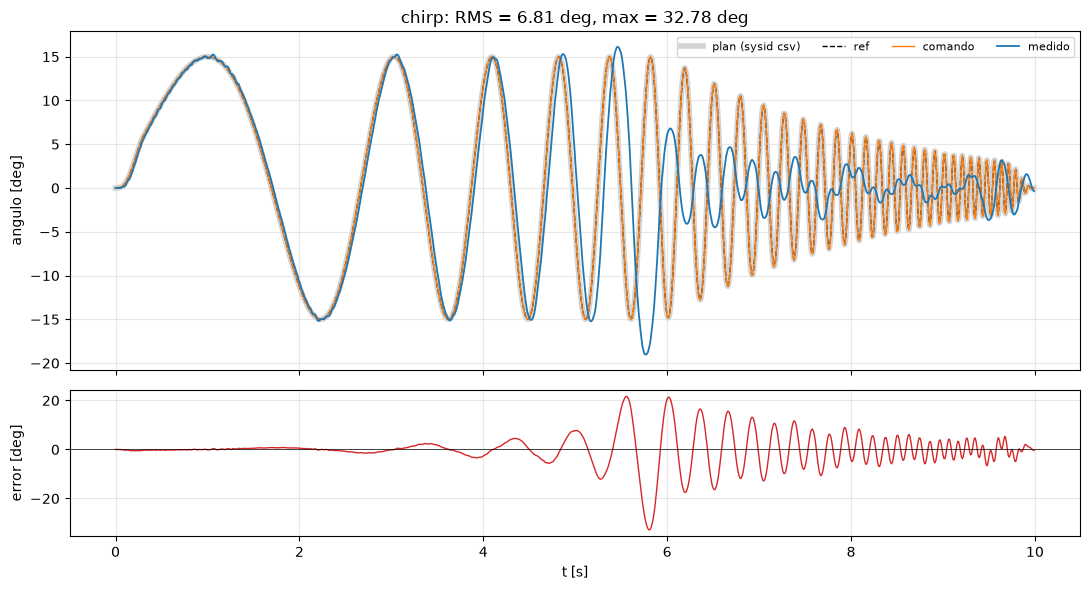

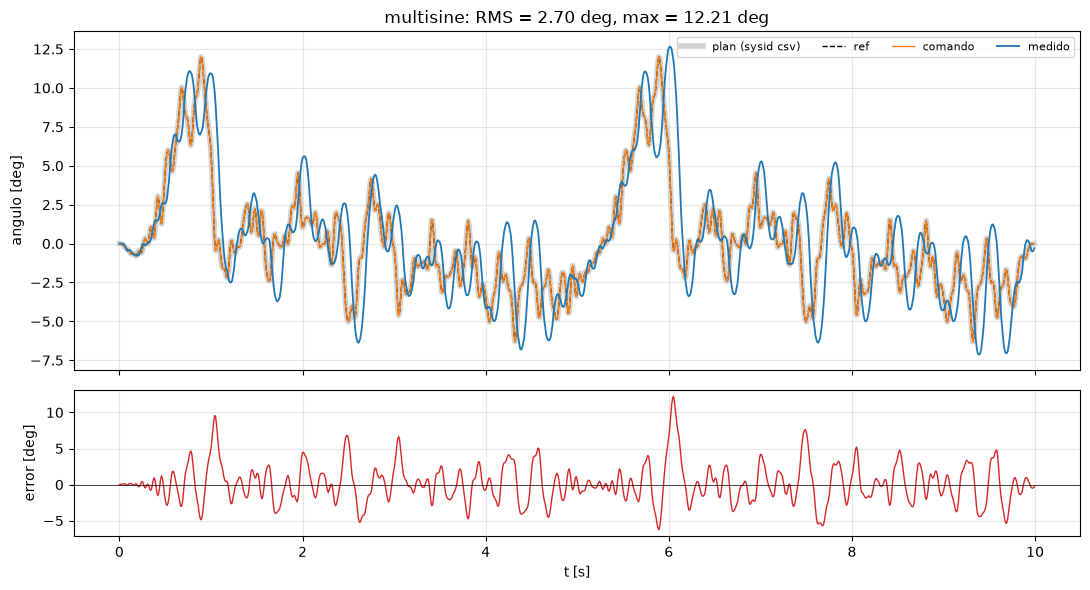

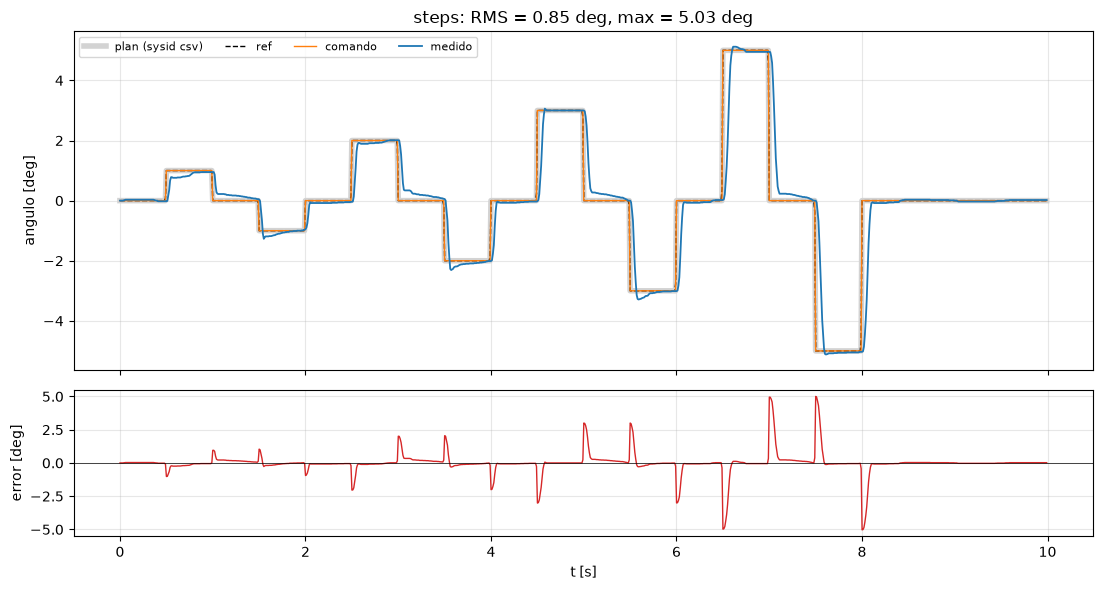

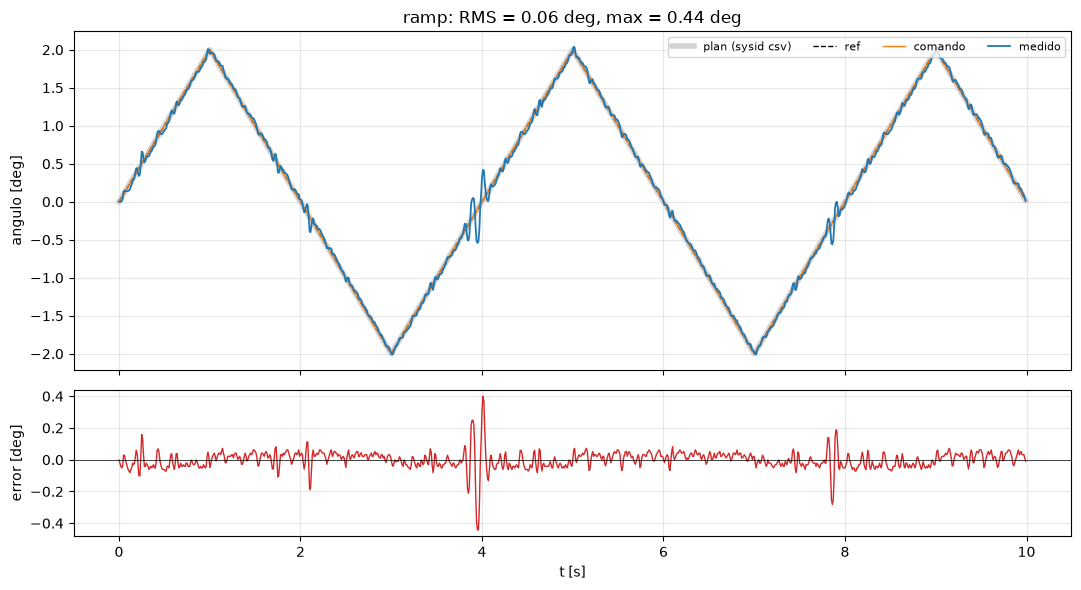

In [3]:
def graficar(s):
    d = ejec[s]
    fig, (a, b) = plt.subplots(2, 1, figsize=(11, 6), sharex=True, gridspec_kw=dict(height_ratios=[3, 1.3]))
    if s in plan:
        a.plot(plan[s]['time_s'], plan[s]['angle_deg'], color='lightgray', lw=4, label='plan (sysid csv)')
    a.plot(d['t_meas_s'], d['ref_deg'], 'k--', lw=1, label='ref')
    a.plot(d['t_cmd_s'], d['cmd_deg'], color='tab:orange', lw=1, label='comando')
    a.plot(d['t_meas_s'], d['meas_deg'], color='tab:blue', lw=1.3, label='medido')
    a.set_ylabel('angulo [deg]'); a.grid(alpha=0.3); a.legend(ncol=4, fontsize=8)
    a.set_title(f'{s}: RMS = {np.sqrt((d.error_deg**2).mean()):.2f} deg, max = {d.error_deg.abs().max():.2f} deg')
    b.plot(d['t_meas_s'], d['error_deg'], color='tab:red', lw=1)
    b.axhline(0, color='k', lw=0.5); b.set_ylabel('error [deg]'); b.set_xlabel('t [s]'); b.grid(alpha=0.3)
    plt.tight_layout(); plt.show()

for s in ejec:
    graficar(s)

## Zoom a una ventana de tiempo

Cambia `SENAL`, `T0` y `T1` para ver el detalle.

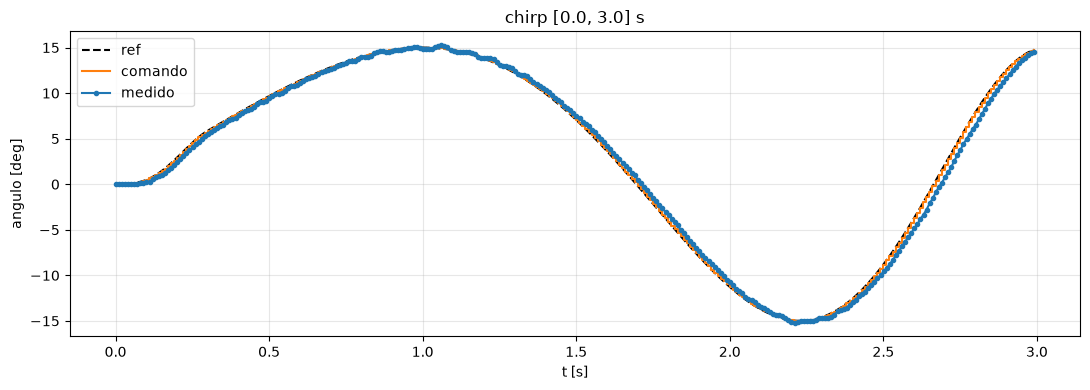

In [4]:
SENAL, T0, T1 = 'chirp', 0.0, 3.0

d = ejec[SENAL]; m = d['t_meas_s'].between(T0, T1); c = d['t_cmd_s'].between(T0, T1)
plt.figure(figsize=(11, 4))
plt.plot(d.t_meas_s[m], d.ref_deg[m], 'k--', label='ref')
plt.step(d.t_cmd_s[c], d.cmd_deg[c], where='post', color='tab:orange', label='comando')
plt.plot(d.t_meas_s[m], d.meas_deg[m], 'o-', ms=3, color='tab:blue', label='medido')
plt.xlabel('t [s]'); plt.ylabel('angulo [deg]'); plt.grid(alpha=0.3); plt.legend(); plt.title(f'{SENAL} [{T0}, {T1}] s')
plt.tight_layout(); plt.show()

## Medido vs. referencia

Si el seguimiento fuera perfecto los puntos caerian sobre la diagonal.

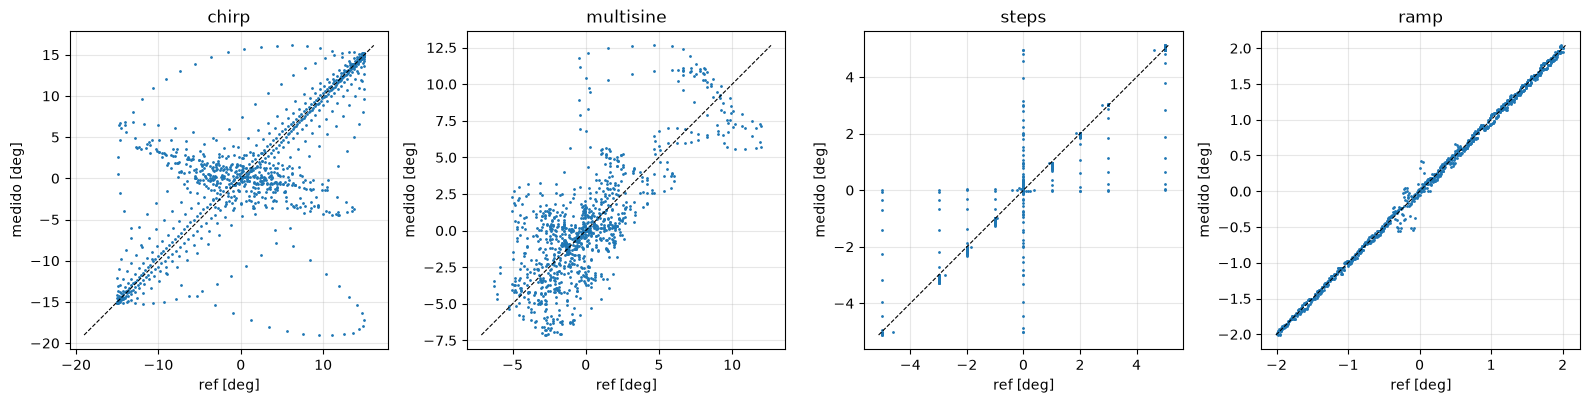

In [5]:
fig, axs = plt.subplots(1, len(ejec), figsize=(4 * len(ejec), 4))
for ax, (s, d) in zip(np.atleast_1d(axs), ejec.items()):
    ax.plot(d.ref_deg, d.meas_deg, '.', ms=2)
    lim = [min(d.ref_deg.min(), d.meas_deg.min()), max(d.ref_deg.max(), d.meas_deg.max())]
    ax.plot(lim, lim, 'k--', lw=0.8); ax.set_aspect('equal'); ax.grid(alpha=0.3)
    ax.set_title(s); ax.set_xlabel('ref [deg]'); ax.set_ylabel('medido [deg]')
plt.tight_layout(); plt.show()

## Respuesta en frecuencia (chirp y multisine)

Cociente de espectros medido/ref: magnitud (dB) y fase. Solo es fiable donde la referencia tiene energia.

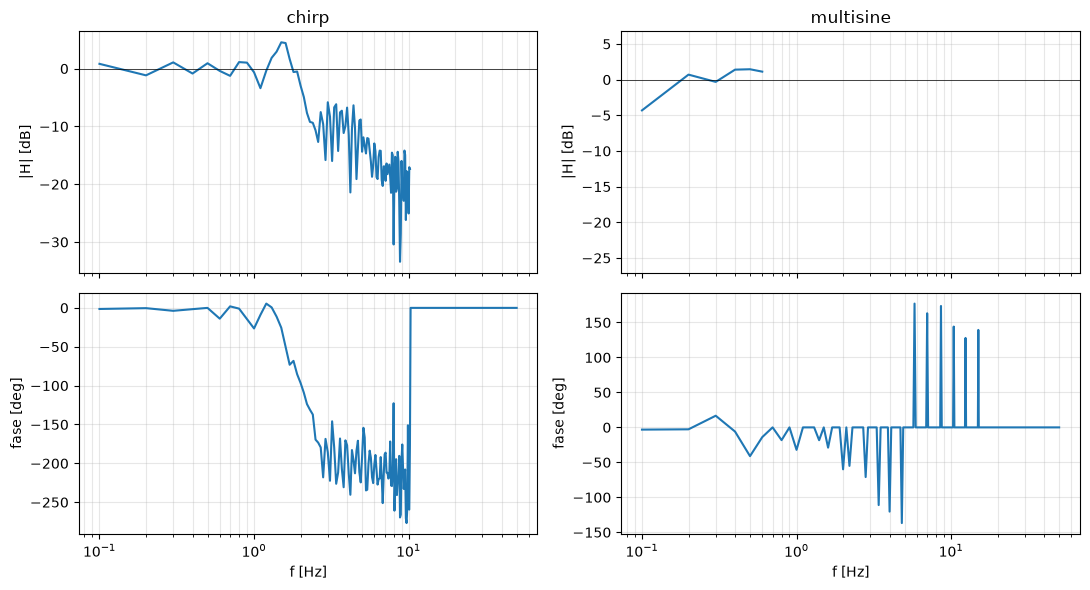

In [6]:
fig, axs = plt.subplots(2, 2, figsize=(11, 6), sharex=True)
for j, s in enumerate([x for x in ('chirp', 'multisine') if x in ejec]):
    d = ejec[s]; t = d.t_meas_s.to_numpy(); dt = np.median(np.diff(t))
    r = d.ref_deg.to_numpy() - d.ref_deg.mean(); y = d.meas_deg.to_numpy() - d.meas_deg.mean()
    f = np.fft.rfftfreq(len(r), dt); R = np.fft.rfft(r); Y = np.fft.rfft(y)
    ok = np.abs(R) > 0.05 * np.abs(R).max()
    H = np.where(ok, Y / np.where(ok, R, 1), np.nan)
    axs[0, j].semilogx(f[1:], 20 * np.log10(np.abs(H[1:]))); axs[0, j].axhline(0, color='k', lw=0.5)
    axs[1, j].semilogx(f[1:], np.rad2deg(np.unwrap(np.angle(np.nan_to_num(H[1:])))))
    axs[0, j].set_title(s); axs[0, j].set_ylabel('|H| [dB]'); axs[1, j].set_ylabel('fase [deg]'); axs[1, j].set_xlabel('f [Hz]')
    for a in axs[:, j]: a.grid(alpha=0.3, which='both')
plt.tight_layout(); plt.show()

# Identificacion de la funcion de transferencia (comando -> posicion)

Todo lo necesario esta en esta seccion (no depende de otros scripts): carga de las `ejecucion_*.csv`, simulacion, ajuste, tabla comparativa, graficas y export.

- **Entrada** `u` = `cmd_deg` (en `t_cmd_s`), **salida** `y` = `meas_deg` (en `t_meas_s`).
- **Modelos**: 1.er, 2.o y 3.er orden, todos con retardo puro `Td`. Se simulan con el comando mantenido entre muestras (ZOH) en una rejilla de 1 kHz y se minimizan los residuos (normalizados por la desviacion de cada archivo) con minimos cuadrados no lineales.
- **Grupos de datos**: `TODOS`, `A` (archivos sin sufijo) y `0x400` (archivos `*_0x400`, modo de control distinto).
- El ajuste tarda unos minutos: el resultado se guarda en `tf_resultados.json`. Pon `REFIT = True` para recalcular.

In [7]:
import json
from scipy import signal, optimize

FS = 1000.0                      # rejilla fina de simulacion [Hz]
REFIT = False                    # True = volver a identificar y sobrescribir el cache
CACHE = DIR / 'tf_resultados.json'

def cargar(f):
    d = pd.read_csv(f)
    return dict(name=Path(f).stem.replace('ejecucion_', ''), tc=d.t_cmd_s.values, u=d.cmd_deg.values,
                tm=d.t_meas_s.values, y=d.meas_deg.values)

def simular(fn, p, ds):
    """Salida simulada en los instantes de medicion. p = [Td, *params].
    El retardo se aplica a la SALIDA con interpolacion lineal (sistema LTI): asi Td es continuo y
    el optimizador puede identificarlo (desplazar la entrada sobre una rejilla de 1 ms lo dejaba
    cuantizado, con gradiente cero)."""
    Td = p[0]; num, den = fn(p[1:])
    t = np.arange(0, ds['tm'][-1] + 0.01, 1 / FS)
    idx = np.clip(np.searchsorted(ds['tc'], t + 1e-4, side='right') - 1, 0, None)   # ZOH (tol. de 0.1 ms)
    _, y, _ = signal.lsim((num, den), ds['u'][idx], t)
    return np.interp(ds['tm'] - Td, t, y)

def ajuste_pct(fn, p, ds):
    e = simular(fn, p, ds) - ds['y']
    return 100 * (1 - np.linalg.norm(e) / np.linalg.norm(ds['y'] - ds['y'].mean())), np.sqrt(np.mean(e ** 2))

def m1(q): K, tau = q;          return [K], [tau, 1]
def m2(q): K, wn, z = q;        return [K * wn**2], [1, 2 * z * wn, wn**2]
def m3(q): K, wn, z, tau = q;   return [K * wn**2], np.polymul([1, 2 * z * wn, wn**2], [tau, 1])

# nombre: (funcion, p0=[Td, ...], cotas inferiores, cotas superiores)
MODELOS = {
    '1er orden': (m1, [0.01, 1, 0.03],            [0, .5, 1e-3],            [0.1, 1.5, 2]),
    '2do orden': (m2, [0.01, 1, 30, 0.7],         [0, .5, 1, .05],          [0.1, 1.5, 300, 5]),
    '3er orden': (m3, [0.01, 1, 30, 0.7, 0.02],   [0, .5, 1, .05, 1e-4],    [0.1, 1.5, 300, 5, 1]),
}

def describir(mn, p):
    Td, q = p[0], p[1:]
    if mn == '1er orden':
        return f'{q[0]:.4f}/({q[1]:.4f}s+1) * exp(-{Td*1e3:.0f}ms s)'
    if mn == '2do orden':
        return (f'{q[0]:.4f}*{q[1]**2:.0f}/(s^2+{2*q[2]*q[1]:.1f}s+{q[1]**2:.0f}) * exp(-{Td*1e3:.0f}ms s)'
                f'  [wn={q[1]/2/np.pi:.2f} Hz, z={q[2]:.2f}]')
    return f'K={q[0]:.3f}, wn={q[1]:.1f}, z={q[2]:.2f}, tau={q[3]:.4f}, Td={Td*1e3:.0f}ms'

ARCH = sorted(DIR.glob('ejecucion_*.csv'))
TODOS = [cargar(f) for f in ARCH]
GRUPOS = {'TODOS': TODOS,
          'A':     [d for d in TODOS if '0x400' not in d['name']],
          '0x400': [d for d in TODOS if '0x400' in d['name']]}
print('Archivos:', {g: [d['name'] for d in v] for g, v in GRUPOS.items()})

Archivos: {'TODOS': ['chirp', 'cihrp_0x400', 'multisine', 'multisine_0x400', 'ramp', 'steps', 'steps_0x400'], 'A': ['chirp', 'multisine', 'ramp', 'steps'], '0x400': ['cihrp_0x400', 'multisine_0x400', 'steps_0x400']}


In [8]:
def identificar():
    res = {}
    for g, sub in GRUPOS.items():
        for mn, (fn, p0, lb, ub) in MODELOS.items():
            r = lambda p: np.concatenate([(simular(fn, p, d) - d['y']) / np.std(d['y']) for d in sub])
            res[f'{g}|{mn}'] = list(optimize.least_squares(r, p0, bounds=(lb, ub), x_scale='jac').x)
            print('ok', g, mn)
    return res

if CACHE.exists() and not REFIT:
    RES = json.load(open(CACHE)); print('Resultados cargados de', CACHE.name)
else:
    RES = identificar(); json.dump(RES, open(CACHE, 'w'), indent=1); print('Guardado', CACHE.name)

# Tabla comparativa: ajuste % de cada modelo sobre cada archivo
filas = []
for k, p in RES.items():
    g, mn = k.split('|'); fn = MODELOS[mn][0]
    fila = {'ajustado con': g, 'modelo': mn, 'Td [ms]': round(p[0] * 1e3, 1), 'G(s)': describir(mn, p)}
    for d in TODOS:
        fila[d['name'].strip('_')] = round(ajuste_pct(fn, p, d)[0])
    filas.append(fila)
tabla = pd.DataFrame(filas)
pd.set_option('display.width', 250, 'display.max_colwidth', 90)
tabla

Resultados cargados de tf_resultados.json


,ajustado con,modelo,Td [ms],G(s),chirp,cihrp_0x400,multisine,multisine_0x400,ramp,steps,steps_0x400
0,TODOS,1er orden,0.0,1.0073/(0.0442s+1) * exp(-0ms s),39,71,54,82,92,85,79
1,TODOS,2do orden,0.0,"1.0065*51282/(s^2+2264.6s+51282) * exp(-0ms s) [wn=36.04 Hz, z=5.00]",39,71,54,82,92,85,79
2,TODOS,3er orden,0.0,"K=1.006, wn=226.9, z=5.00, tau=0.0001, Td=0ms",39,71,54,82,92,85,79
3,A,1er orden,27.3,1.0038/(0.0487s+1) * exp(-27ms s),45,48,60,63,87,86,63
4,A,2do orden,0.0,"0.9842*385/(s^2+25.7s+385) * exp(-0ms s) [wn=3.12 Hz, z=0.65]",48,42,61,60,88,83,62
5,A,3er orden,0.0,"K=0.984, wn=19.7, z=0.66, tau=0.0001, Td=0ms",48,42,61,60,88,83,62
6,0x400,1er orden,5.3,1.0130/(0.0146s+1) * exp(-5ms s),26,88,44,90,94,73,86
7,0x400,2do orden,0.0,"1.0109*9273/(s^2+180.5s+9273) * exp(-0ms s) [wn=15.33 Hz, z=0.94]",26,89,44,90,95,73,85
8,0x400,3er orden,0.0,"K=1.012, wn=300.0, z=1.95, tau=0.0066, Td=0ms",26,89,44,90,95,73,86


## Modelo recomendado por modo

Con `Td` libre (continuo), el retardo y el orden del modelo se compensan entre si: el 2.o y 3.er orden salen con `Td = 0` y ajustan casi igual que el 1.er orden con retardo. Por parsimonia se usa **1.er orden + retardo** en los tres grupos; el 2.o orden queda en la tabla como alternativa (en el modo A, wn ~ 3.1 Hz, z ~ 0.65).
**Ojo:** `Td` esta mal determinado con muestreo a 100 Hz (ver el perfil de `Td` mas abajo); lo robusto es la constante de tiempo efectiva y la ganancia ~ 1.

[A] 1er orden: G(s) = 1.0038/(0.0487s+1) * exp(-27ms s)
[0x400] 1er orden: G(s) = 1.0130/(0.0146s+1) * exp(-5ms s)
[TODOS] 1er orden: G(s) = 1.0073/(0.0442s+1) * exp(-0ms s)


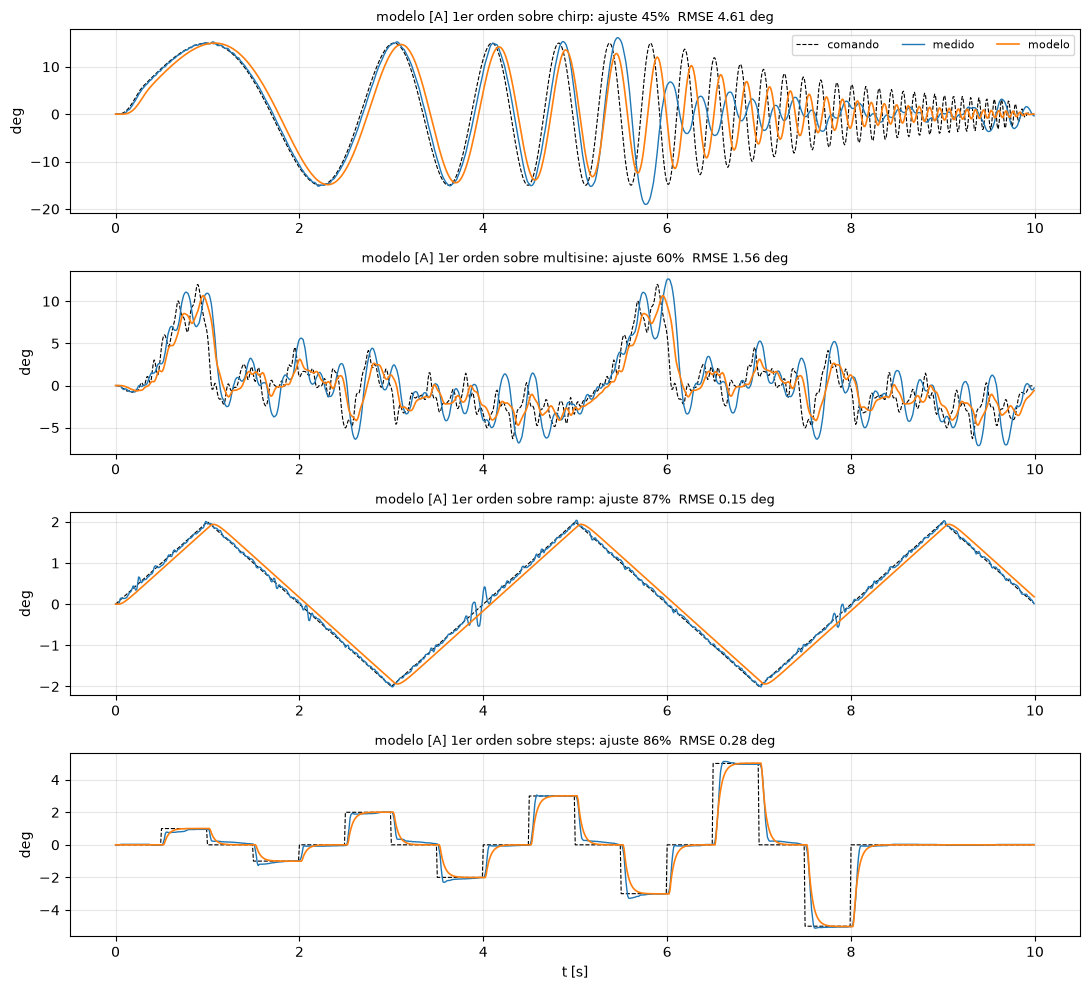

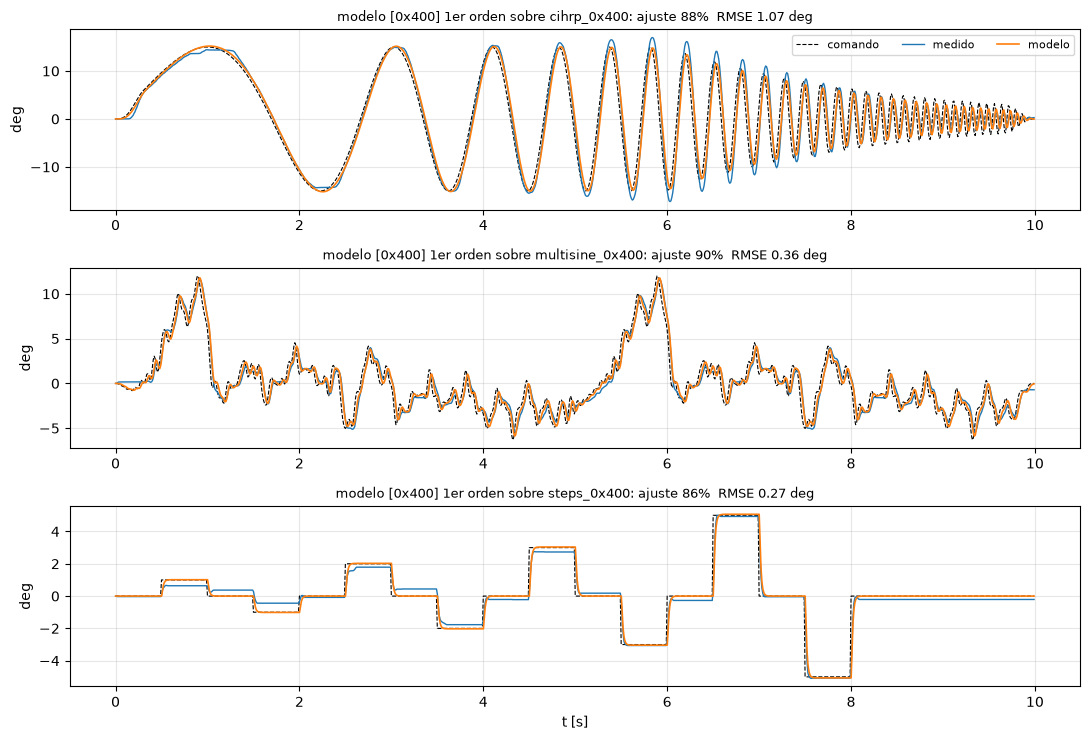

In [9]:
ELEGIDO = {'A': '1er orden', '0x400': '1er orden', 'TODOS': '1er orden'}
for g, mn in ELEGIDO.items():
    p = RES[f'{g}|{mn}']
    print(f'[{g}] {mn}: G(s) = {describir(mn, p)}')

def graficar_modelo(g, mn, archivos=None):
    fn = MODELOS[mn][0]; p = RES[f'{g}|{mn}']; sub = archivos or GRUPOS[g]
    fig, axs = plt.subplots(len(sub), 1, figsize=(11, 2.5 * len(sub)))
    for ax, d in zip(np.atleast_1d(axs), sub):
        a, r = ajuste_pct(fn, p, d)
        ax.plot(d['tc'], d['u'], 'k--', lw=.8, label='comando')
        ax.plot(d['tm'], d['y'], lw=1, label='medido')
        ax.plot(d['tm'], simular(fn, p, d), lw=1.2, label='modelo')
        ax.set_title(f"modelo [{g}] {mn} sobre {d['name'].strip('_')}: ajuste {a:.0f}%  RMSE {r:.2f} deg", fontsize=9)
        ax.grid(alpha=.3); ax.set_ylabel('deg')
    np.atleast_1d(axs)[0].legend(ncol=3, fontsize=8); np.atleast_1d(axs)[-1].set_xlabel('t [s]')
    fig.tight_layout(); plt.show()

graficar_modelo('A', ELEGIDO['A'])
graficar_modelo('0x400', ELEGIDO['0x400'])

## Modelo de `TODOS` (un solo modelo para todos los datos) sobre cada archivo

Sirve para ver cuanto se pierde al forzar un unico modelo lineal para los dos modos.

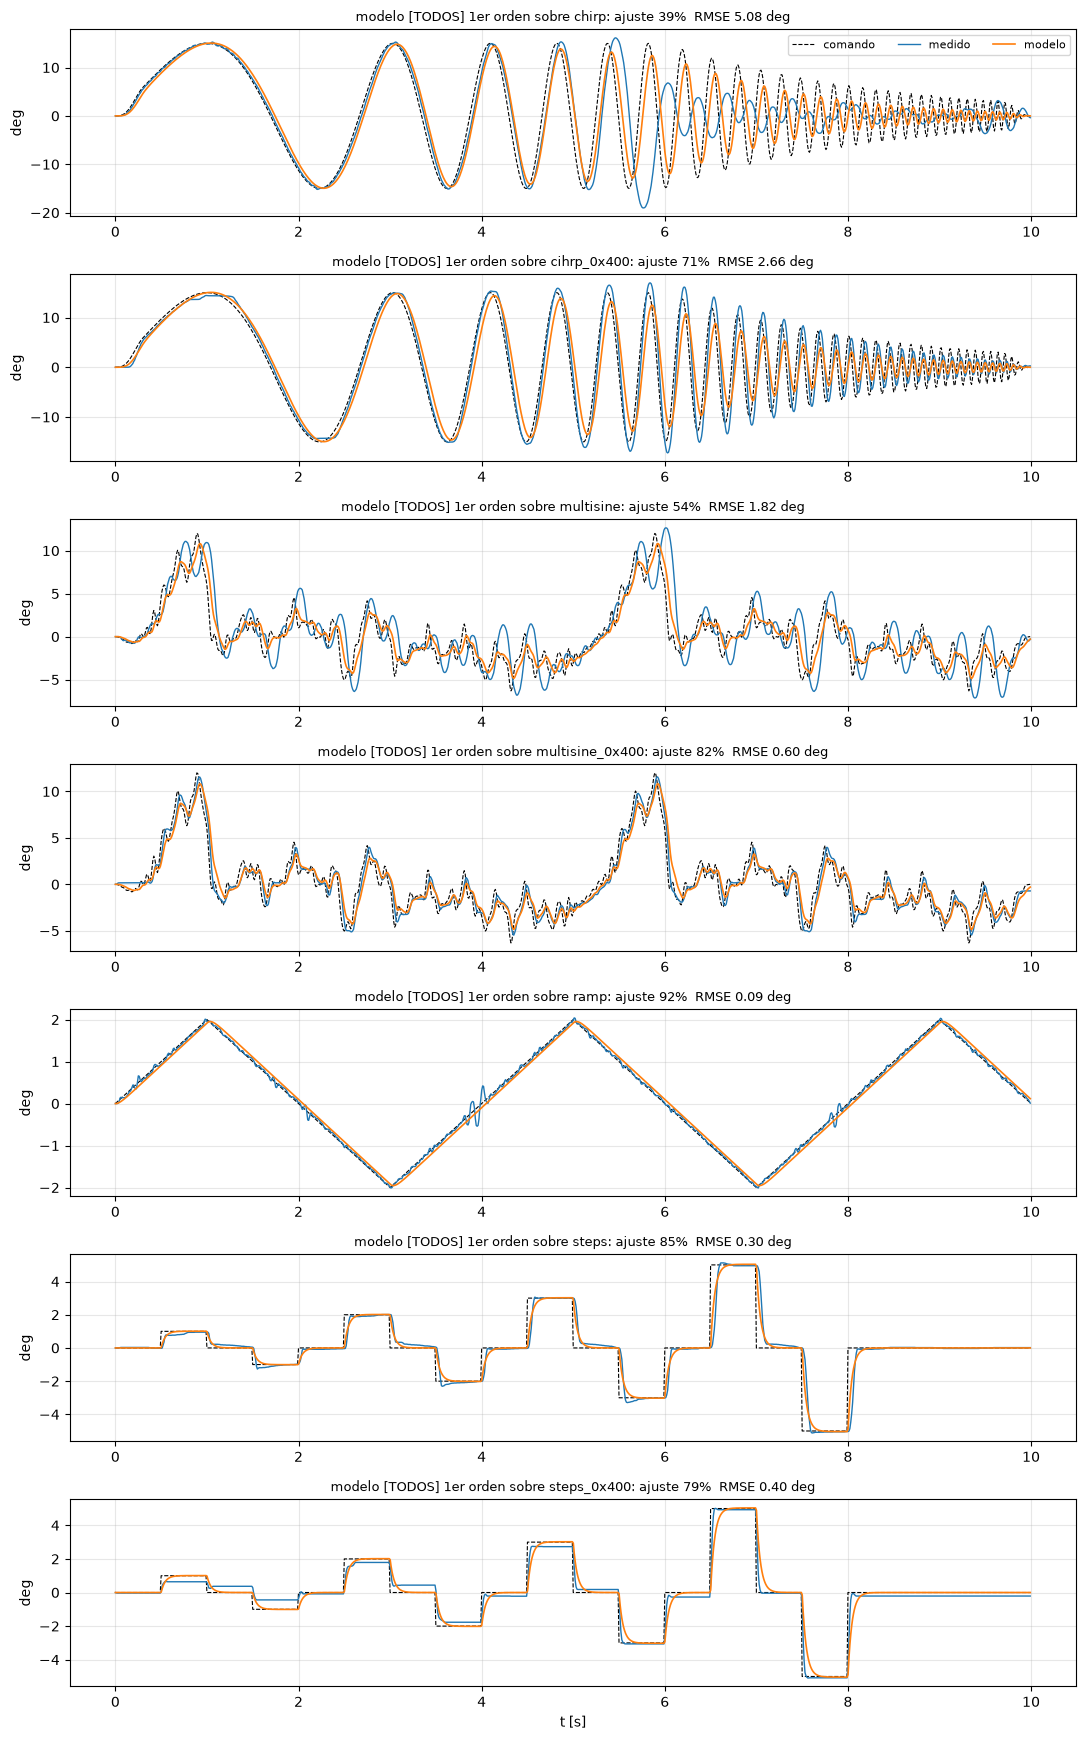

In [10]:
graficar_modelo('TODOS', ELEGIDO['TODOS'], TODOS)

## Explorar cualquier combinacion

Cambia `GRUPO`, `MODELO` y `SOLO` (lista de archivos, o `None` para todos los del grupo) para ver el ajuste de cualquier modelo.

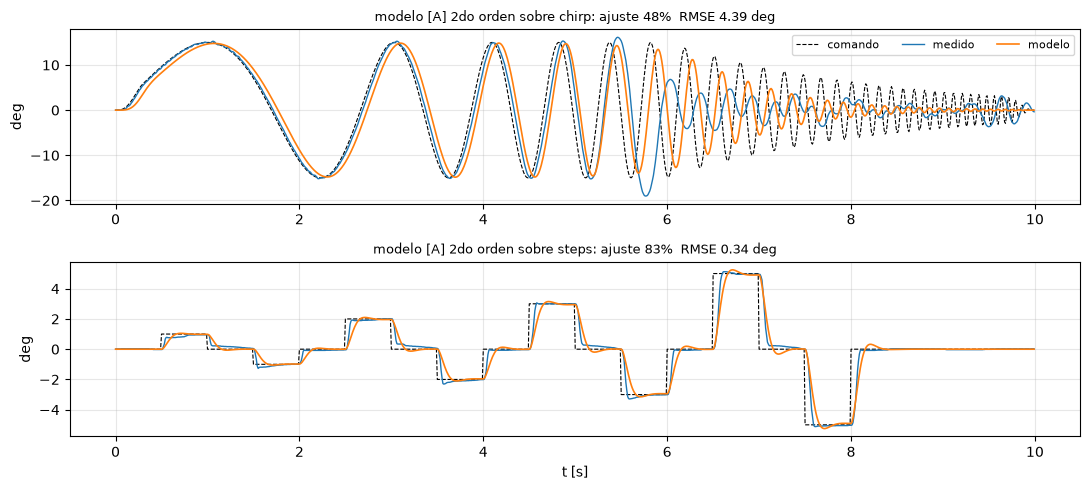

In [11]:
GRUPO, MODELO, SOLO = 'A', '2do orden', ['chirp', 'steps']   # SOLO = None -> todos los del grupo
sel = None if SOLO is None else [d for d in TODOS if d['name'].strip('_') in SOLO]
graficar_modelo(GRUPO, MODELO, sel)

## Bode y escalon de los modelos recomendados

Magnitud y fase incluyen el retardo puro; la respuesta al escalon se desplaza `Td`.

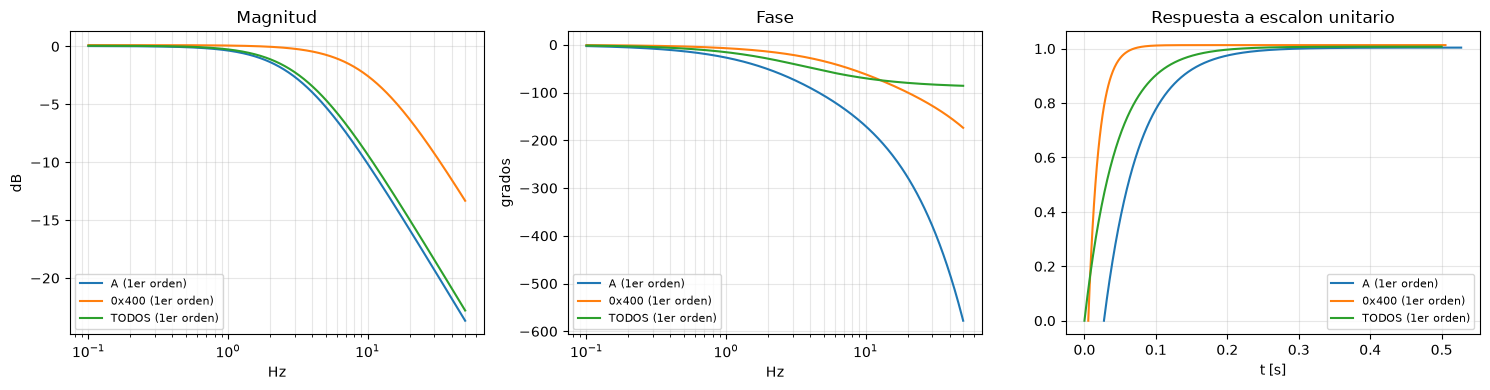

In [12]:
f = np.logspace(-1, np.log10(50), 400); w = 2 * np.pi * f
fig, (a, b, c) = plt.subplots(1, 3, figsize=(15, 4))
for g, mn in ELEGIDO.items():
    p = RES[f'{g}|{mn}']; num, den = MODELOS[mn][0](p[1:])
    _, H = signal.freqs(num, den, w); H = H * np.exp(-1j * w * p[0])
    a.semilogx(f, 20 * np.log10(abs(H)), label=f'{g} ({mn})')
    b.semilogx(f, np.unwrap(np.angle(H)) * 180 / np.pi, label=f'{g} ({mn})')
    t = np.linspace(0, 0.5, 1000); _, y = signal.step((num, den), T=t)
    c.plot(t + p[0], y, label=f'{g} ({mn})')
a.set(title='Magnitud', xlabel='Hz', ylabel='dB'); b.set(title='Fase', xlabel='Hz', ylabel='grados')
c.set(title='Respuesta a escalon unitario', xlabel='t [s]')
for ax in (a, b, c): ax.grid(alpha=.3, which='both'); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

## Incertidumbre del retardo `Td` (perfil)

Se fija `Td` en una rejilla (0-60 ms) y se reajusta el resto de los parametros del modelo recomendado. La curva de coste muestra cuanto "sabe" el dato sobre `Td`: se reporta el rango donde el coste esta a menos de 5 % del minimo (criterio heuristico, no un intervalo de confianza formal).

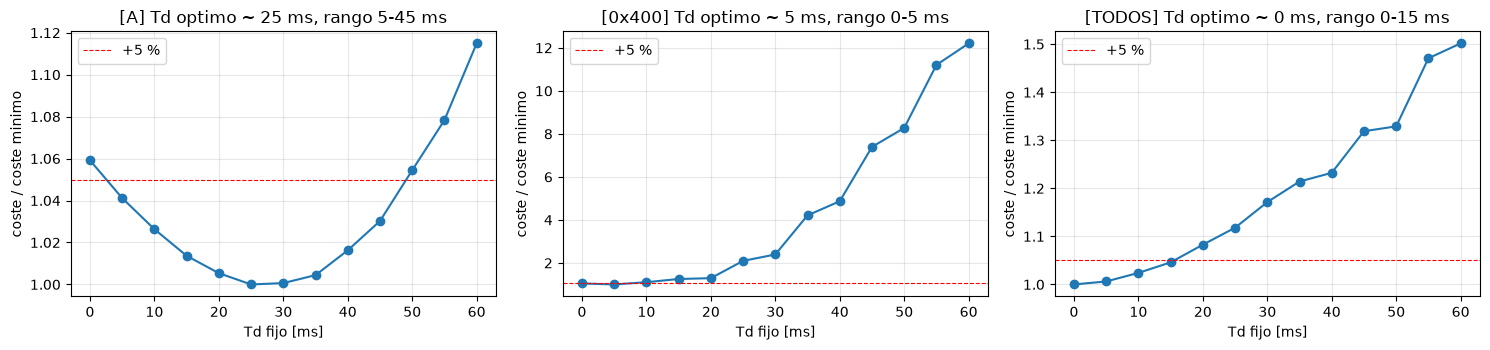

{'A': '5-45 ms (optimo 25)', '0x400': '0-5 ms (optimo 5)', 'TODOS': '0-15 ms (optimo 0)'}


In [13]:
PERFIL_F = DIR / 'tf_perfil.json'
TDS = np.arange(0, 0.0601, 0.005)

def perfil(g, mn):
    fn, p0, lb, ub = MODELOS[mn]; sub = GRUPOS[g]; costes, pars = [], []
    for Td in TDS:
        r = lambda q: np.concatenate([(simular(fn, [Td, *q], d) - d['y']) / np.std(d['y']) for d in sub])
        s = optimize.least_squares(r, p0[1:], bounds=(lb[1:], ub[1:]), x_scale='jac')
        costes.append(s.cost); pars.append(list(s.x))
    return dict(Td=list(TDS), coste=costes, params=pars)

if PERFIL_F.exists() and not REFIT:
    PERFIL = json.load(open(PERFIL_F))
else:
    PERFIL = {g: perfil(g, mn) for g, mn in ELEGIDO.items()}; json.dump(PERFIL, open(PERFIL_F, 'w'), indent=1)

RANGO_TD = {}
fig, axs = plt.subplots(1, len(PERFIL), figsize=(5 * len(PERFIL), 3.6))
for ax, (g, pf) in zip(np.atleast_1d(axs), PERFIL.items()):
    c = np.array(pf['coste']); td = np.array(pf['Td']) * 1e3; ok = c <= 1.05 * c.min()
    RANGO_TD[g] = (td[ok].min(), td[ok].max(), td[c.argmin()])
    ax.plot(td, c / c.min(), 'o-'); ax.axhline(1.05, color='r', ls='--', lw=.8, label='+5 %')
    ax.set(title=f'[{g}] Td optimo ~ {RANGO_TD[g][2]:.0f} ms, rango {RANGO_TD[g][0]:.0f}-{RANGO_TD[g][1]:.0f} ms',
           xlabel='Td fijo [ms]', ylabel='coste / coste minimo'); ax.grid(alpha=.3); ax.legend()
plt.tight_layout(); plt.show()
print({g: f'{a:.0f}-{b:.0f} ms (optimo {c:.0f})' for g, (a, b, c) in RANGO_TD.items()})

## Exportar los modelos recomendados

In [14]:
out = {g: dict(modelo=mn, Td_s=RES[f'{g}|{mn}'][0], params=RES[f'{g}|{mn}'][1:], G=describir(mn, RES[f'{g}|{mn}']), Td_rango_ms=list(RANGO_TD[g][:2]))
       for g, mn in ELEGIDO.items()}
json.dump(out, open(DIR / 'tf_por_modo.json', 'w'), indent=1, ensure_ascii=False)
print('Guardado tf_por_modo.json'); out

Guardado tf_por_modo.json


{'A': {'modelo': '1er orden',
  'Td_s': 0.02730387977905921,
  'params': [1.003823675936989, 0.04873682583214668],
  'G': '1.0038/(0.0487s+1) * exp(-27ms s)',
  'Td_rango_ms': [np.float64(5.0), np.float64(45.0)]},
 '0x400': {'modelo': '1er orden',
  'Td_s': 0.005340280763591637,
  'params': [1.0129645664540181, 0.014612171384488929],
  'G': '1.0130/(0.0146s+1) * exp(-5ms s)',
  'Td_rango_ms': [np.float64(0.0), np.float64(5.0)]},
 'TODOS': {'modelo': '1er orden',
  'Td_s': 8.556195456473341e-16,
  'params': [1.0073034910419394, 0.04416136144359902],
  'G': '1.0073/(0.0442s+1) * exp(-0ms s)',
  'Td_rango_ms': [np.float64(0.0), np.float64(15.0)]}}